# Carryover and saturation: what a linear VECM gets wrong

**Audience:** analysts who have read the practitioner guide (01) and the comparison with `statsmodels` (02).

**What this notebook does:** guide 02 showed that on clean data `BayesianVECM` and `statsmodels` give the same estimates. Brand data is rarely that clean. Two features of real marketing data break a linear same-week model, and `statsmodels` cannot fit either:

| Feature | What it means | `statsmodels` | `BayesianVECM` |
|---|---|---|---|
| Carryover (adstock) | Spend keeps working for weeks after it runs | Same-week effect only, or one free coefficient per lag you add by hand | `adstock=`: one decay per channel |
| Saturation | Each extra £ buys less as spend grows | Linear | `saturation=`: a logistic curve per channel |

The data is simulated with both in the truth so every estimate can be checked. Each section compares three things: the `statsmodels` fit, the Bayesian fit with both options and the truth. Same-week links between the brand metrics are harder to identify and have their own guide (04).

In [1]:
# Sampling configuration, as in the other guides.
FAST_SAMPLING = True

if FAST_SAMPLING:
    DRAWS, TUNE, CHAINS = 1000, 1000, 2
else:
    DRAWS, TUNE, CHAINS = 2000, 1000, 4

LEVEL = 0.90  # every interval in this notebook is a 90% interval
TAILS = (100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2)

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.vector_ar.vecm import VECM

from bayesian_vecm import BayesianVECM, simulate_brand_data

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)
BAYES_COLOUR, SM_COLOUR, TRUTH_COLOUR = "#2a78d6", "#eb6834", "black"
SPEC = {"k_ar_diff": 1, "coint_rank": 2, "deterministic": "co"}
SALES, AWARE = "organic_sales", "brand_awareness"
CHANNELS = ["brand_spend", "pr_reach", "sponsorship_reach"]

## 1. The data

The default simulated brand from the other guides, 260 weeks, with two changes to the truth:

- **Carryover:** each channel acts through geometric adstock. The decays are 0.5 for brand spend, 0.3 for PR and 0.6 for sponsorship.
- **Saturation:** each channel acts through a logistic curve. Brand spend and sponsorship have `lam = 5` and PR `lam = 3`. At average spend one more unit is worth about half the average return.

With saturation on, the channels are **raw spend** with an average of 1, not deviations from the average. The two macro drivers are unchanged.

In [3]:
DECAYS = {"brand_spend": 0.5, "pr_reach": 0.3, "sponsorship_reach": 0.6}
LAMBDAS = {"brand_spend": 5.0, "pr_reach": 3.0, "sponsorship_reach": 5.0}

data = simulate_brand_data(exog_adstock=DECAYS, exog_saturation=LAMBDAS)
endog, exog, truth = data.endog, data.exog, data.truth
names, drivers = list(endog.columns), list(exog.columns)
print(exog[CHANNELS].describe().loc[["mean", "min", "max"]].round(2))

      brand_spend  pr_reach  sponsorship_reach
mean         0.98      1.05               0.96
min          0.42      0.50               0.39
max          2.23      2.38               2.37


## 2. The two fits

**`statsmodels`** fits the VECM with every driver in the same week, as in guide 02.

**`BayesianVECM`** adds `adstock=CHANNELS` and `saturation=CHANNELS`. The macro drivers stay linear and same-week. Adstock comes first and saturation acts on the adstocked spend, as in most MMMs.

In [4]:
sm = VECM(endog, exog=exog, **SPEC).fit()
model = BayesianVECM(
    **SPEC,
    adstock=CHANNELS,
    saturation=CHANNELS,
).fit(
    endog,
    exog=exog,
    draws=DRAWS,
    tune=TUNE,
    chains=CHAINS,
    target_accept=0.95,
    random_seed=14,
    progressbar=False,
)
post = model.idata_.posterior

summary = model.summary().apply(pd.to_numeric, errors="coerce")
print(f"Divergences:   {int(model.idata_.sample_stats['diverging'].sum())}")
print(f"Max r-hat:     {summary['r_hat'].max():.3f}")
print(f"Min bulk ESS:  {summary['ess_bulk'].min():.0f}")


def draws(name):
    values = post[name].values
    return values.reshape(-1, *values.shape[2:])


def interval(x):
    lo, hi = np.percentile(x, TAILS)
    return f"{np.mean(x):.4f} ({lo:.4f} to {hi:.4f})"


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())


def across_seeds(results, fits):
    # Median relative error and 90% coverage per quantity and fit, across seeds.
    results = results[results.fit.isin(fits)].assign(error=lambda d: d["median"] / d.truth - 1)
    table = results.groupby(["quantity", "fit"], sort=False).agg(
        error=("error", "median"), coverage=("covered", "mean"), seeds=("seed", "nunique")
    )
    table["error"] = table["error"].map("{:+.0%}".format)
    table["coverage"] = table["coverage"].map("{:.0%}".format)
    return table.unstack("fit")

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, adstock_alpha, B_total, saturation_lam, B_free]


Divergences:   0
Max r-hat:     1.005
Min bulk ESS:  909


## 3. Carryover: how much of the effect lands after the first week?

**Plain English:** a TV burst this week still lifts awareness next week and the week after. A model that only looks at the same week sees the first slice and misses the rest.

`statsmodels` puts each driver in the same week. To get carryover you add lagged copies of the spend columns by hand, one free coefficient per lag. `adstock=` gives each channel two numbers instead: the **total effect** (`B_total`) and a **decay** shared across the series. The half-life is the number of weeks for the effect to halve.

In [5]:
aware = names.index(AWARE)
b_total = draws("B_total")  # (draw, series, adstocked channel)
decay = draws("adstock_alpha")  # (draw, adstocked channel)
sm_b = sm.det_coef[:, 1:]  # the constant is column 0

rows = []
for c, ch in enumerate(CHANNELS):
    j = drivers.index(ch)
    w_true = truth.adstock[j]
    rows.append(
        {
            "channel": ch,
            "total effect, truth": truth.b_total[aware, j],
            "statsmodels (same week)": sm_b[aware, j],
            "BayesianVECM": interval(b_total[:, aware, c]),
            "decay, truth": w_true,
            "decay, BayesianVECM": interval(decay[:, c]).replace(".0000", ""),
            "half-life (weeks), truth": np.log(0.5) / np.log(w_true),
            "half-life, BayesianVECM": np.median(np.log(0.5) / np.log(decay[:, c])),
        }
    )
pd.DataFrame(rows).set_index("channel").T

channel,brand_spend,pr_reach,sponsorship_reach
"total effect, truth",0.018,0.012,0.006
statsmodels (same week),0.009771,0.008129,0.002956
BayesianVECM,0.0226 (0.0155 to 0.0301),0.0158 (0.0103 to 0.0217),-0.0013 (-0.0108 to 0.0060)
"decay, truth",0.5,0.3,0.6
"decay, BayesianVECM",0.6075 (0.4659 to 0.7245),0.4260 (0.2332 to 0.5920),0.6596 (0.1571 to 0.9778)
"half-life (weeks), truth",1.0,0.575717,1.356915
"half-life, BayesianVECM",1.416741,0.829057,2.096151


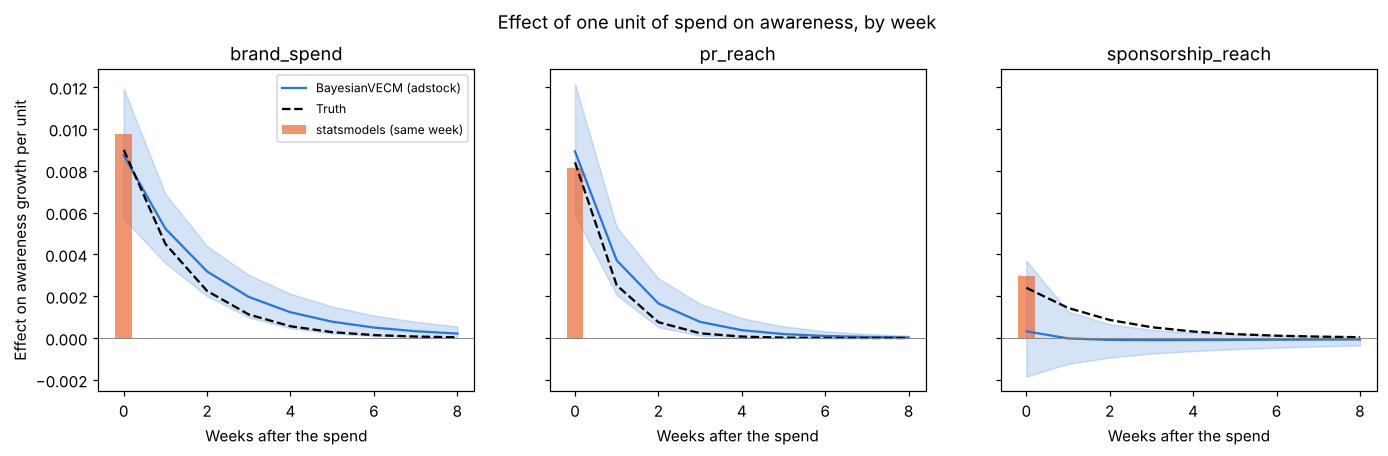

In [6]:
lags = np.arange(9)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for c, (ax, ch) in enumerate(zip(axes, CHANNELS, strict=True)):
    j = drivers.index(ch)
    w = truth.adstock[j]
    true_path = truth.b_total[aware, j] * (1 - w) * w**lags
    post_path = b_total[:, aware, c, None] * (1 - decay[:, c, None]) * decay[:, c, None] ** lags
    lo, hi = np.percentile(post_path, TAILS, axis=0)
    ax.fill_between(lags, lo, hi, color=BAYES_COLOUR, alpha=0.2)
    ax.plot(lags, post_path.mean(axis=0), color=BAYES_COLOUR, label="BayesianVECM (adstock)")
    ax.plot(lags, true_path, color=TRUTH_COLOUR, ls="--", label="Truth")
    ax.bar(
        [0],
        [sm_b[aware, j]],
        width=0.4,
        color=SM_COLOUR,
        alpha=0.7,
        label="statsmodels (same week)",
    )
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(ch)
    ax.set_xlabel("Weeks after the spend")
axes[0].set_ylabel("Effect on awareness growth per unit")
axes[0].legend(fontsize=8)
fig.suptitle("Effect of one unit of spend on awareness, by week", y=1.02)
plt.show()

**Reading the table and chart.**

- `statsmodels` sees only the first week. Its brand spend coefficient (0.0098) is close to the true week-0 effect (0.0090) but about half the total (0.018).
- The adstock fit recovers the shape of the decay for brand spend and PR. On this data set it puts their totals 25% to 30% high, and the truth sits inside both intervals.
- Sponsorship is the smallest effect (0.006). On 260 weeks it cannot be told apart from zero. Its decay interval runs from 0.17 to 0.98, which says as much.

One data set can be lucky or unlucky. `tools/adstock_check.py` fitted 18 simulated data sets with the same carryover, each with a same-week model and with `adstock=`. The same-week fit is the Bayesian one, which matches `statsmodels` (guide 02):

In [7]:
adstock_runs = pd.read_csv(ROOT / "tools" / "adstock_check_results.csv")
carryover = adstock_runs[
    (adstock_runs.setting == "carryover") & adstock_runs.quantity.str.startswith("total")
]
across_seeds(carryover, ["same week", "adstock"])

error          coverage             seeds        
fit                      same week adstock same week adstock same week adstock
quantity                                                                      
total: brand_spend            -46%     -2%        0%     89%        18      18
total: pr_reach               -28%     +1%       61%     94%        18      18
total: sponsorship_reach      -48%     +5%       61%     94%        18      18

The same-week fit misses about half of each total. Its interval contains the truth in 0% to 61% of data sets. The adstock fit is within 5% on the median with coverage of 89% to 94%.

## 4. Saturation: what happens when the budget moves a long way?

**Plain English:** the first £1,000 of brand spend buys more awareness than the tenth. A linear model draws a straight line through the spend levels it has seen. Near average spend that is close enough. For a big move, such as switching brand off or doubling it, the straight line is badly wrong.

`saturation=` fits a logistic curve per channel. `model.saturation_curve(channel, levels)` returns the posterior of the effect on each series of holding spend at each level for good, relative to its average contribution. For `statsmodels` the same quantity is its coefficient times the change in spend.

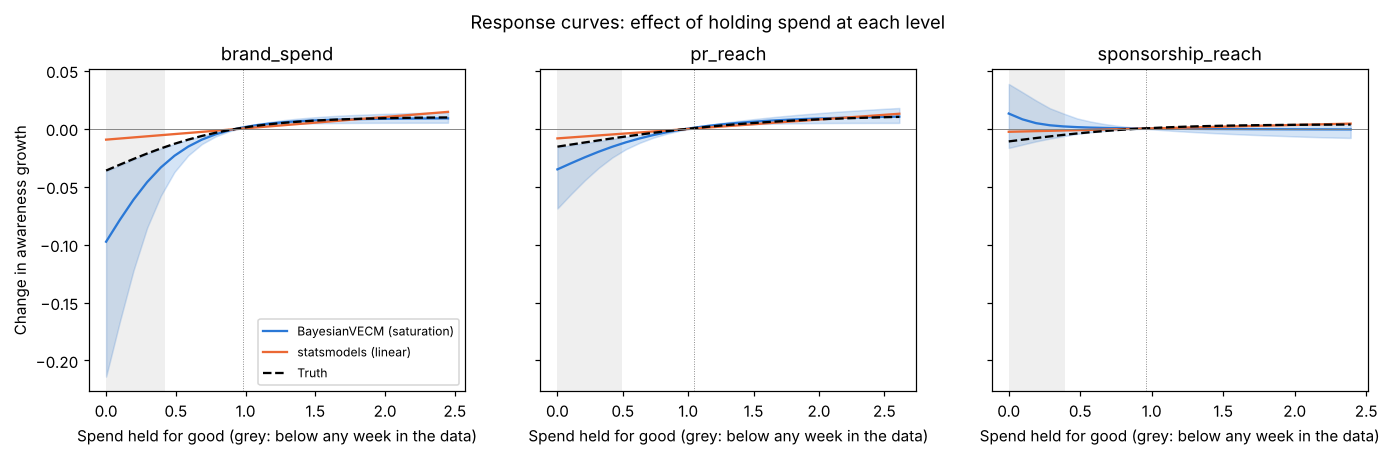

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, ch in zip(axes, CHANNELS, strict=True):
    j = drivers.index(ch)
    mean = float(exog[ch].mean())
    levels = np.linspace(0, 2.5 * mean, 26)
    curve = model.saturation_curve(ch, levels).sel(response_variable=AWARE).values
    curve = curve.reshape(-1, len(levels))
    lo, hi = np.percentile(curve, TAILS, axis=0)
    ax.fill_between(levels, lo, hi, color=BAYES_COLOUR, alpha=0.2)
    ax.plot(levels, curve.mean(axis=0), color=BAYES_COLOUR, label="BayesianVECM (saturation)")
    ax.plot(levels, sm_b[aware, j] * (levels - mean), color=SM_COLOUR, label="statsmodels (linear)")
    ax.plot(
        levels, truth.response(ch, levels)[:, aware], color=TRUTH_COLOUR, ls="--", label="Truth"
    )
    ax.axvspan(0, exog[ch].min(), color="grey", alpha=0.12, lw=0)
    ax.axvline(mean, color="grey", lw=0.6, ls=":")
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(ch)
    ax.set_xlabel("Spend held for good (grey: below any week in the data)")
axes[0].set_ylabel("Change in awareness growth")
axes[0].legend(fontsize=8)
fig.suptitle("Response curves: effect of holding spend at each level", y=1.02)
plt.show()

In [9]:
MOVES = {"switched off": 0.0, "halved": 0.5, "up a half": 1.5, "doubled": 2.0}
rows = []
for ch in ["brand_spend", "pr_reach"]:
    j = drivers.index(ch)
    mean = float(exog[ch].mean())
    levels = [mean * k for k in MOVES.values()]
    curve = model.saturation_curve(ch, levels).sel(response_variable=AWARE).values
    curve = curve.reshape(-1, len(levels))
    true = truth.response(ch, levels)[:, aware] - truth.response(ch, mean)[aware]
    base = model.saturation_curve(ch, [mean]).sel(response_variable=AWARE).values.reshape(-1, 1)
    for i, move in enumerate(MOVES):
        sm_move = sm_b[aware, j] * (levels[i] - mean)
        bayes = curve[:, i] - base[:, 0]
        rows.append(
            {
                "channel": ch,
                "spend": move,
                "truth": true[i],
                "statsmodels": sm_move,
                "statsmodels error": f"{sm_move / true[i] - 1:+.0%}",
                "BayesianVECM": interval(bayes),
                "BayesianVECM error": f"{np.median(bayes) / true[i] - 1:+.0%}",
            }
        )
pd.DataFrame(rows).set_index(["channel", "spend"])

truth  statsmodels statsmodels error                  BayesianVECM BayesianVECM error
channel     spend                                                                                                 
brand_spend switched off -0.036933    -0.009580              -74%  -0.0986 (-0.2155 to -0.0373)              +122%
            halved       -0.013856    -0.004790              -65%  -0.0245 (-0.0388 to -0.0138)               +69%
            up a half     0.005945     0.004790              -19%     0.0059 (0.0034 to 0.0086)                -3%
            doubled       0.008122     0.009580              +18%     0.0073 (0.0038 to 0.0119)               -13%
pr_reach    switched off -0.015978    -0.008503              -47%  -0.0359 (-0.0703 to -0.0166)              +100%
            halved       -0.007181    -0.004251              -41%  -0.0126 (-0.0190 to -0.0075)               +71%
            up a half     0.004953     0.004251              -14%     0.0057 (0.0030 to 0.0084)               +14%
            doubled       0.007984     0.008503               +6%     0.0083 (0.0036 to 0.0137)                -0%

**Reading the chart and table.**

- Near average spend all three lines agree. Raising spend by a half is within 20% for both fits.
- Cutting spend is where the straight line fails. `statsmodels` understates the loss from switching brand spend off by 74%. It misses the carryover and it cannot bend.
- Increases look better for `statsmodels` than they should. Its same-week coefficient is about half the total effect and its straight line overstates gains at high spend. On this data set the two errors cancel.
- The saturation fit overstates the switch-off loss here. No week had brand spend below 0.42 (the grey band), so zero spend is an extrapolation. Its interval is wide (-0.22 to -0.04) and contains the truth.

Across the 18 data sets of `tools/saturation_check.py` the picture is clearer than on any one of them. Both fits there include adstock, so the difference is the curve alone:

In [10]:
saturation_runs = pd.read_csv(ROOT / "tools" / "saturation_check_results.csv")
steps = saturation_runs[
    (saturation_runs.setting == "saturating")
    & saturation_runs.quantity.str.startswith("step")
    & ~saturation_runs.quantity.str.endswith("sponsorship_reach")
]
across_seeds(steps, ["linear", "saturation"])

error            coverage             seeds           
fit                    linear saturation   linear saturation linear saturation
quantity                                                                      
step x0: brand_spend     -60%       -10%       0%       100%     18         18
step x0.5: brand_spend   -43%        -7%       6%        89%     18         18
step x1.5: brand_spend   +50%        -4%      56%       100%     18         18
step x2: brand_spend    +123%        -6%      17%       100%     18         18
step x0: pr_reach        -26%        +2%      72%        83%     18         18
step x0.5: pr_reach      -19%        +3%      89%        78%     18         18
step x1.5: pr_reach      +22%        -3%      89%        94%     18         18
step x2: pr_reach        +52%        -4%      67%        94%     18         18

- The linear fit understates the loss from switching brand spend off by 60% and overstates the gain from doubling it by 123%. Its intervals contain the truth in 0% and 17% of data sets.
- The saturation fit is within 10% on the median for every move of brand spend and PR. Its coverage is 78% to 100%.
- This data set (seed 14) is the worst of the 18 for the saturation fit at zero spend. The other 17 put the switch-off loss within about 50%.

## 5. What this means

- **Carryover is the bigger error for reporting.** A same-week model misses about half of each channel's effect. `adstock=` gets the total and the half-life.
- **Saturation is the bigger error for planning.** A straight line is fine near current spend and wrong for cuts and big increases. `saturation=` gets the curve and says how unsure it is where the data is thin.
- **Read extrapolations through their intervals.** Spend levels outside anything in the data give wide intervals. Trust a switch-off figure only as far as its interval allows.

**How the options were checked.** Each option was validated on many simulated data sets with a known answer, not just this one. The scripts and their results are in `tools/`:

- `tools/adstock_check.py`: carryover, 18 seeds.
- `tools/saturation_check.py`: saturation, 33 seeds across four settings.

**With your own data.**

- `adstock=` and `saturation=` need raw spend for the saturated channels. Keep the macro drivers as they are.
- With no saturation in your data the default prior still bends the curve a little. Effects far from current spend can come out up to 30% too large for brand spend. Compare the fit with a linear one before relying on a switch-off figure.
- Adstock with no carryover in the data estimates decays near zero at no cost.